# Loaded Q, unloaded Q and EOM voltage gain from a one-port $S_{11}$ measurement

Following Kwok and Liang [1].

## Overview

We measure the reflection coefficient $\rho = S_{11}$ of the EOM's parallel LC tank with a VNA. From that one-port measurement alone we extract the resonant frequency $f_0$, the loaded, unloaded and external quality factors $Q_L$, $Q_u$, $Q_e$, the coupling coefficient $\beta$ and, given $L$ or $C_\mathrm{eff}$, the voltage gain $G$ across the EOM.

**Method**

1. **Model (Sections 1–2).** Kwok and Liang's resonator model. The power that is not reflected, $1 - |\rho|^2$, is a Lorentzian whose width is set by $Q_L$ alone.
2. **Loaded Q (Sections 3–4).** The half-power points sit at $Q_L\Omega = \pm 1$. We find their associated dB thresholds on the $S_{11}$ trace, allowing us to calculate the resonator's bandwidth. Combined with the resonant frequency, this gives loaded Q.
3. **Coupling and unloaded Q (Sections 5–6).** $|\rho_0|$ allows two values of $\beta$, differentiated by whether or not the Smith-chart circle encloses the origin. Determining $\beta$ gives us the external and unloaded Q factors.
4. **Gain (Section 7).** Balance the power accepted at the port against the power dissipated in the tank to calculate EOM gain.
5. **Analysis (Sections 8–13).** Apply these results to an experimental $S_{11}$ measurement.

**Primary results**

Band-edge level and loaded Q:

$$S_{11,\mathrm{edge}}\,[\mathrm{dB}] = 10\log_{10}\!\left[\frac{1 + 10^{S_{11,0}\,[\mathrm{dB}]/10}}{2}\right], \qquad Q_L = \frac{f_0}{f_2 - f_1}$$

Coupling, chosen by the Smith chart:

$$\beta = \frac{1 - |\rho_0|}{1 + |\rho_0|}\ \ \text{(circle excludes the origin)} \qquad\text{or}\qquad \beta = \frac{1 + |\rho_0|}{1 - |\rho_0|}\ \ \text{(circle encloses the origin)}$$

Unloaded and external Q:

$$Q_u = (1 + \beta)\,Q_L, \qquad Q_e = \frac{Q_u}{\beta}$$

Voltage gain across the EOM at resonance, relative to the incident-wave amplitude $V^+$:

$$G = \frac{|V_\mathrm{EOM}|}{|V^+|} = \sqrt{\frac{Q_u\,(1 - |\rho_0|^2)}{\omega_0\,C_\mathrm{eff}\,Z_0}} = \sqrt{\frac{Q_u\,(1 - |\rho_0|^2)\,\omega_0 L}{Z_0}}$$

**Data file**

Enter the Touchstone file to analyze: an `.s1p`, or an `.s2p` whose first S-parameter is $S_{11}$. All the code from Section 8 on runs on this file. The gain in Section 12 also needs $L$ or $C_\mathrm{eff}$; enter those in `cases` there. The example file, `19cm_tank_s11_cal.s1p`, is $S_{11}$ of the EOM tank from 30 to 45 MHz (101 000 points, 149 Hz step, $Z_0 = 50\ \Omega$).

In [1]:
FILE = "19cm_tank_s11_cal.s1p"      # Touchstone file to analyze

import os
assert os.path.exists(FILE), f"{FILE} not found in {os.getcwd()}"

## 1. Resonator model

Kwok and Liang model a one-port resonator as a series $r$–$L$–$C$ driven from the input coupling resistance $r_A$ (the 50 Ω line referred to the resonator through a lossless inverter). The reflection coefficient of this setup is:

$$\rho = \frac{(r - r_A) + j\left(\omega L - \dfrac{1}{\omega C}\right)}{(r + r_A) + j\left(\omega L - \dfrac{1}{\omega C}\right)}.$$

With

$$\text{Resonant Frequency}\quad \omega_0 = \frac{1}{\sqrt{LC}}, \quad \text{Coupling Coefficient}\quad\beta = \frac{r_A}{r}, \quad \text{Unloaded Q} \quad Q_u = \frac{\omega_0 L}{r},$$ $$\text{External Q} \quad Q_e = \frac{\omega_0 L}{r_A} = \frac{Q_u}{\beta}, \quad \text{Loaded Q} \quad Q_L = \frac{\omega_0 L}{r + r_A}, \quad \Omega \equiv \frac{\omega}{\omega_0} - \frac{\omega_0}{\omega},$$

we have $1/Q_L = 1/Q_u + 1/Q_e$, so

$$Q_u = (1 + \beta)\,Q_L .$$

Using $\omega L - 1/\omega C = \omega_0 L\,\Omega$ and dividing by $r$:

$$\rho(\Omega) = \frac{1 - \beta + jQ_u\Omega}{1 + \beta + jQ_u\Omega}, \qquad \rho_0 \equiv \rho(0) = \frac{1-\beta}{1+\beta}, \qquad |\rho_0| = 10^{S_{11,0}[\mathrm{dB}]/20}.$$

## 2. Power not reflected is $|S_{21}|^2$ of an equivalent two-port

Treat $r$ as the termination of a second port. Between port 1 ($r_A$) and port 2 ($r$) there is only the lossless series reactance $jX = j(\omega L - 1/\omega C)$, so

$$S_{11} = \frac{r - r_A + jX}{r_A + r + jX} = \rho, \qquad
|S_{21}|^2 = \frac{4 r_A r}{(r + r_A)^2 + X^2} = \frac{4\beta}{(1+\beta)^2 + (Q_u\Omega)^2}.$$

Adding, $|\rho|^2 + |S_{21}|^2 = \dfrac{(1-\beta)^2 + (Q_u\Omega)^2 + 4\beta}{(1+\beta)^2 + (Q_u\Omega)^2} = 1$. With $Q_u/(1+\beta) = Q_L$,

$$|S_{21}(\Omega)|^2 = 1 - |\rho(\Omega)|^2 = \frac{|S_{21,0}|^2}{1 + (Q_L\Omega)^2}, \qquad |S_{21,0}|^2 = \frac{4\beta}{(1+\beta)^2} = 1 - |\rho_0|^2 .$$

The absorbed power is a Lorentzian whose width depends only on $Q_L$; $\beta$ sets only its height.

## 3. Half-power bandwidth: $Q_L\Omega = \pm 1$

We wish to find the frequencies where the transmitted power is halved, i.e$$|S_{21}|^2 = \tfrac12 |S_{21,0}|^2 \iff 1 + (Q_L\Omega)^2 = 2 \iff Q_L\Omega = \pm 1 .$$

With $\Omega = \omega/\omega_0 - \omega_0/\omega$ these frequencies are defined as $\omega^2 \mp (\omega_0/Q_L)\,\omega - \omega_0^2 = 0$, with positive roots $\omega_{2,1} = \tfrac{\omega_0}{2}\left[\sqrt{4 + Q_L^{-2}} \pm Q_L^{-1}\right]$. Rearranging in terms of true frequencies $f_{1,2}$ :

$$f_2 - f_1 = \frac{f_0}{Q_L}, \qquad f_1 f_2 = f_0^2 .$$

## 4. The $S_{11}$ level at which to read the bandwidth

At the band edges $1 - |\rho(f_{1,2})|^2 = \tfrac12(1 - |\rho_0|^2)$, so

$$|\rho(f_{1,2})|^2 = \frac{1 + |\rho_0|^2}{2}, \qquad
\boxed{S_{11,\mathrm{edge}}\,[\mathrm{dB}] = 10\log_{10}\!\left[\frac{1 + 10^{S_{11,0}\,[\mathrm{dB}]/10}}{2}\right]}$$

This is an absolute level on the trace (referenced to 0 dB), not an offset from the bottom of the dip. It is $-3.01$ dB only in the limit $|\rho_0| \to 0$. Using this definition of $S_{11,\mathrm{edge}}$, we can find the bandwidth of a resonator and thus calculate its loaded Q factor.

## 5. Loaded and unloaded Q

1. Read off $f_0$ and $S_{11,0}$ at lowest point of $S_{11}$ trace; Calculate resonant reflection coefficient $|\rho_0| = 10^{S_{11,0}/20}$.
2. Find $f_1 < f_0 < f_2$ where the trace crosses $S_{11,\mathrm{edge}}$; Calculate $\;Q_L = f_0/(f_2 - f_1)$.
3. Invert $\rho_0 = (1-\beta)/(1+\beta)$. The magnitude fixes $\beta$ only up to the sign of $\rho_0$:
$$\beta = \begin{cases} \dfrac{1 - |\rho_0|}{1 + |\rho_0|} < 1, & \rho_0 > 0 \ \text{(under-coupled)}, \\[8pt] \dfrac{1 + |\rho_0|}{1 - |\rho_0|} > 1, & \rho_0 < 0 \ \text{(over-coupled)}. \end{cases}$$
4. Determine the sign of $\beta$ from the resonator's Smith chart (see Section 6 below). If the circle traced in the Smith chart includes the origin, the resonator is over-coupled and $\beta > 1$. If the circle excludes the origin, the resonator is under-coupled and $\beta < 1$.
5. Then we can calculate the resonator's unloaded Q factor $Q_u = (1+\beta)\,Q_L$ and $Q_e = Q_u/\beta$.

## 6. Sign of $\rho_0$ from the Smith chart

### 6.1 Rewriting $\rho$

Start from Section 1 and add and subtract $2\beta$ in the numerator:

$$\rho(\Omega) = \frac{(1 + \beta + jQ_u\Omega) - 2\beta}{1 + \beta + jQ_u\Omega} = 1 - \frac{2\beta}{1 + \beta + jQ_u\Omega}.$$

Factor $(1+\beta)$ out of the denominator and use $Q_u/(1+\beta) = Q_L$:

$$\rho(\Omega) = 1 - \frac{2\beta}{1+\beta}\cdot\frac{1}{1 + jQ_L\Omega} \;=\; 1 - D\,w,$$

with

$$D \equiv \frac{2\beta}{1+\beta}, \qquad w \equiv \frac{1}{1 + jt}, \qquad t \equiv Q_L\Omega .$$

$w$ is a dimensionless complex number that depends only on the normalized detuning $t$. $t$ is real, $t = 0$ at resonance and $t = \pm 1$ at the band edges $f_{1,2}$ (Section 3). All of the coupling dependence sits in the real constant $D$, which runs from 0 ($\beta = 0$) through 1 ($\beta = 1$) toward 2 ($\beta \to \infty$).

### 6.2 $w$ traces a circle

Multiplying by the conjugate, $w = \dfrac{1 - jt}{1 + t^2}$, so $\;\mathrm{Re}\,w = \dfrac{1}{1+t^2}$, $\;\mathrm{Im}\,w = \dfrac{-t}{1+t^2}$.

The distance of $w$ from the point $\tfrac12$ is

$$w - \tfrac12 = \frac{2 - (1 + jt)}{2(1 + jt)} = \frac12\,\frac{1 - jt}{1 + jt}
\quad\Rightarrow\quad
\left|w - \tfrac12\right| = \frac12\,\frac{|1 - jt|}{|1 + jt|} = \frac12,$$

because $1 - jt$ and $1 + jt$ are complex conjugates with the same modulus $\sqrt{1 + t^2}$. So for every real $t$, $w$ lies on the circle with center $\tfrac12$ and radius $\tfrac12$:

| $t$ | $w$ | where on the circle | meaning |
|:---:|:---:|:---:|:---|
| $\pm\infty$ | $0$ | left end | far from resonance |
| $-1$ | $\tfrac12(1 + j)$ | top | lower band edge $f_1$ |
| $0$ | $1$ | right end | resonance $f_0$ |
| $+1$ | $\tfrac12(1 - j)$ | bottom | upper band edge $f_2$ |

$\Omega$, and therefore $t$, increases with $f$. For $t < 0$, $\mathrm{Im}\,w > 0$, so as the frequency rises $w$ leaves 0, goes over the top to 1 and returns along the bottom: it runs **clockwise**.

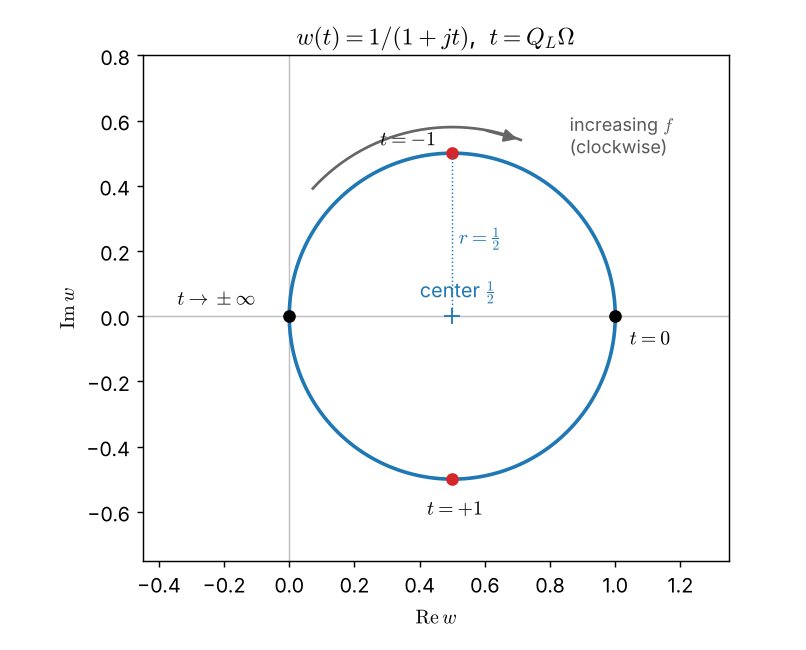

### 6.3 From $w$ to $\rho$

$\rho = 1 - D\,w$ is three operations on the $w$ circle:

1. **Scale by $D$:** center $D/2$, radius $D/2$. The circle still passes through 0.
2. **Negate:** center $-D/2$, radius $D/2$. This is a 180° rotation about the origin, so the trace still runs clockwise.
3. **Add 1:** center $1 - D/2$, radius $D/2$.

Substituting $D = 2\beta/(1+\beta)$:

$$\text{center} = 1 - \frac{\beta}{1+\beta} = \frac{1}{1+\beta}, \qquad \text{radius} = \frac{\beta}{1+\beta}.$$

| $t$ | $\rho$ | where on the circle |
|:---:|:---:|:---|
| $\pm\infty$ | $+1$ | detuned point (total reflection) |
| $-1$ | $\dfrac{1}{1+\beta} - j\dfrac{\beta}{1+\beta}$ | bottom ($f_1$) |
| $0$ | $\rho_0 = 1 - D = \dfrac{1-\beta}{1+\beta}$ | opposite the detuned point |
| $+1$ | $\dfrac{1}{1+\beta} + j\dfrac{\beta}{1+\beta}$ | top ($f_2$) |

The diameter lies on the real axis from $\rho_0$ to $+1$, so its length is

$$d = 1 - \rho_0 = D = \frac{2\beta}{1+\beta} \quad\Rightarrow\quad \beta = \frac{d}{2-d}.$$

The half-power points are the top and bottom of the circle, 90° from the diameter as seen from the center.

### 6.4 Enclosure of Origin

The origin is inside the circle if and only if its distance from the center is less than the radius:

$$\frac{1}{1+\beta} < \frac{\beta}{1+\beta} \iff \beta > 1 .$$

Equivalently, the circle crosses the real axis only at $+1$ and $\rho_0$, so it straddles the origin exactly when $\rho_0 < 0$.

| coupling | $\beta$ | $\rho_0$ | $d = D$ | origin |
|:---|:---:|:---:|:---:|:---|
| under | $< 1$ | $> 0$ | $< 1$ | outside the circle |
| critical | $= 1$ | $0$ | $1$ | on the circle |
| over | $> 1$ | $< 0$ | $> 1$ | inside the circle |

In the figure, $\beta = 0.5$ and $\beta = 2$ give the same $|\rho_0| = 1/3$, i.e. the same $-9.5$ dB dip on a $|S_{11}|$ plot, but only the over-coupled circle encloses the origin. This is why the magnitude alone cannot choose the $\beta$ branch in Section 5.

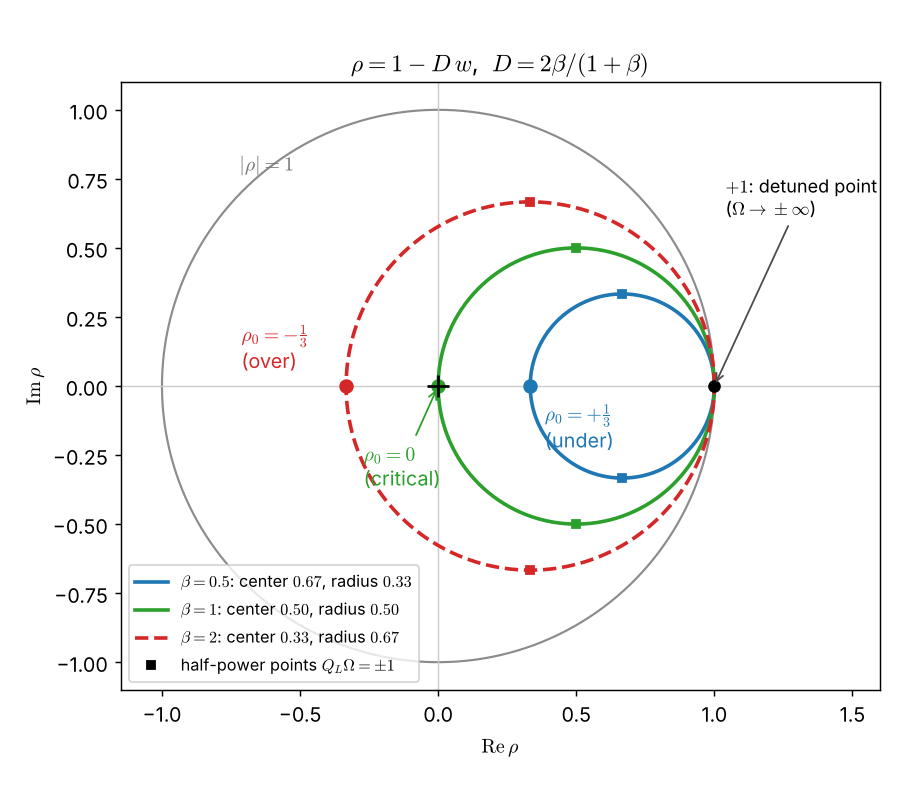

### 6.5 Fitting the measured circle

Sections 6.1–6.4 describe the ideal $\rho$. The circle the VNA actually records is rotated by any line length beyond the calibration plane and shrunk slightly by line loss. For a parallel tank (our case) it is also rotated by 180°, because swapping series for parallel swaps impedance for admittance and flips the sign of $\rho$. Each of these multiplies $\rho$ by one complex constant $K$, so the recorded trace is

$$\rho_\mathrm{meas} = K\,(1 - D\,w) = A + \frac{B}{1 + jQ_L\Omega}, \qquad A = K, \quad B = -D\,K .$$

This is the form fitted in Section 10. $A$ is the detuned point and $A + B$ is the reflection at resonance. Where $A$ lands depends on the cable and coupling network, but $K$ cancels in the ratio $|B|/|A| = D = d$, so $\beta = d/(2-d)$ still holds. A rotation or scaling about the origin also cannot change whether the circle encloses the origin.

## 7. Voltage gain across the EOM

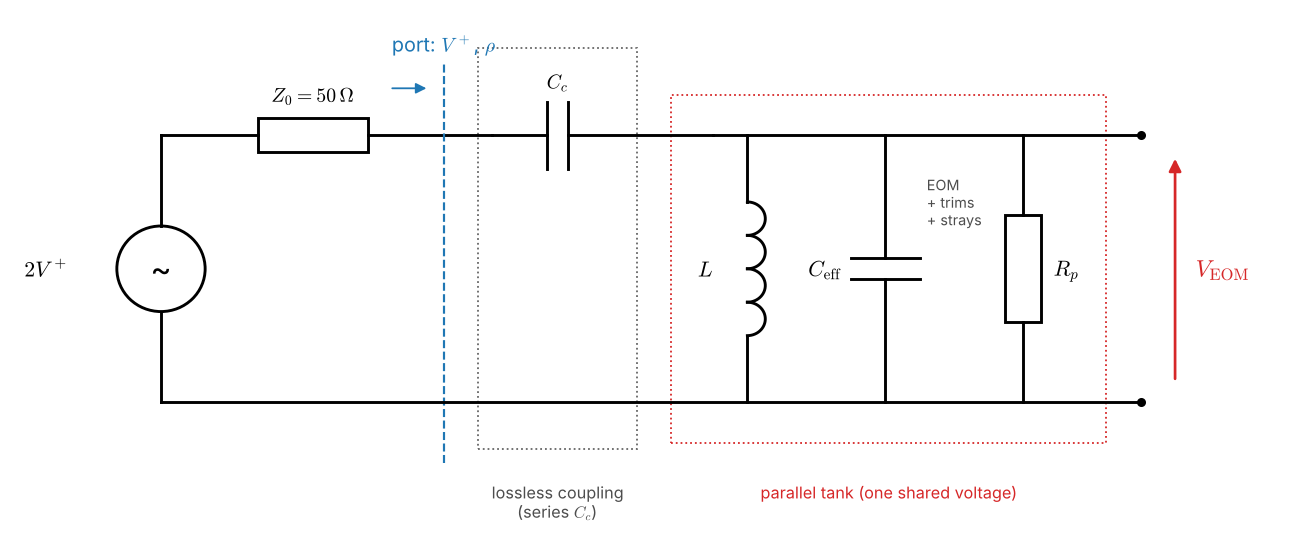

The source is a matched generator with EMF $2V^+$ and internal impedance $Z_0$. $V^+$ is the incident-wave amplitude, i.e. the generator's "amplitude into 50 Ω" setting. It feeds the tank through a lossless coupling network (the series $C_c$). Throughout this section the tank is a **parallel** LC: $L$, $C_\mathrm{eff}$ and $R_p$ are connected in parallel, with the EOM directly across $L$, so all three share the single voltage $V_\mathrm{EOM}$. $R_p$ lumps all internal loss (coil resistance, EOM dielectric loss, trim capacitors) into one parallel resistor at resonance. The goal is $G \equiv |V_\mathrm{EOM}|/|V^+|$ at $f_0$.

### 7.1 Phasors and time-averaged power

A sinusoid is written $v(t) = \mathrm{Re}\{V e^{j\omega t}\} = |V|\cos(\omega t + \phi_V)$, so $|V|$ is the **peak** amplitude. The time-averaged power with current phasor $I$ is

$$\bar P = \frac{1}{T}\int_0^T v(t)\,i(t)\,dt = \frac{1}{2}\,\mathrm{Re}\{V I^*\},$$

where the $\tfrac12$ is the average of $\cos^2$ over a period. On the line, the incident wave has $I^+ = V^+/Z_0$ with $Z_0$ real, so

$$P_\mathrm{inc} = \tfrac12\,\mathrm{Re}\left\{V^+\left(\frac{V^+}{Z_0}\right)^{\!*}\right\} = \frac{|V^+|^2}{2Z_0}.$$

The same $\tfrac12$ appears in the power in a resistor, $|V|^2/2R$, and in stored energy, $\tfrac12 L|I|^2$. With RMS phasors ($|V_\mathrm{rms}| = |V|/\sqrt2$) it disappears: $P_\mathrm{inc} = |V^+_\mathrm{rms}|^2/Z_0$. Every power and energy below carries the same $\tfrac12$, so it cancels in $G$. $G$ is the same ratio for peak, RMS or peak-to-peak amplitudes, as long as $V^+$ and $V_\mathrm{EOM}$ use the same convention.

### 7.2 Power in

At resonance the fraction of incident power that is not reflected is $1 - |\rho_0|^2$ (Section 2). The coupling network is lossless and $R_p$ is the only dissipative element, so all of that power is dissipated in $R_p$:

$$P_\mathrm{loss} = (1 - |\rho_0|^2)\,P_\mathrm{inc} = (1 - |\rho_0|^2)\,\frac{|V^+|^2}{2Z_0}.$$

### 7.3 Stored energy in the parallel tank

Because $L$ and $C_\mathrm{eff}$ are in parallel, at $\omega_0$ they have the same voltage $v(t) = |V_\mathrm{EOM}|\cos\omega_0 t$ and carry equal and opposite currents:

$$w_C(t) = \tfrac12 C_\mathrm{eff}\,v^2 = \tfrac12 C_\mathrm{eff}|V_\mathrm{EOM}|^2\cos^2\omega_0 t,$$

$$i_L(t) = \frac{|V_\mathrm{EOM}|}{\omega_0 L}\sin\omega_0 t, \qquad
w_L(t) = \tfrac12 L\,i_L^2 = \frac{|V_\mathrm{EOM}|^2}{2\,\omega_0^2 L}\sin^2\omega_0 t .$$

Since $\omega_0^2 L C_\mathrm{eff} = 1$, the two prefactors are equal, and the total

$$W = w_C + w_L = \tfrac12 C_\mathrm{eff}|V_\mathrm{EOM}|^2 = \frac{|V_\mathrm{EOM}|^2}{2\,\omega_0^2 L}$$

is constant in time: the energy sloshes between $C_\mathrm{eff}$ and $L$. This is the step where the parallel topology matters. The EOM sees the full tank voltage because it sits directly across $L$. Trim capacitors in parallel share that voltage, so they affect $G$ only through $C_\mathrm{eff}$.

### 7.4 Power out

The unloaded Q is defined by internal loss only:

$$Q_u = \frac{\omega_0 W}{P_\mathrm{loss}}.$$

The source's loading counts toward $Q_e$, not $Q_u$. In the parallel tank $R_p$ also sees $V_\mathrm{EOM}$, so $P_\mathrm{loss} = |V_\mathrm{EOM}|^2/2R_p$, which gives $Q_u = \omega_0 C_\mathrm{eff} R_p = R_p/\omega_0 L$. Hence

$$P_\mathrm{loss} = \frac{\omega_0 W}{Q_u} = \frac{|V_\mathrm{EOM}|^2}{2\,Q_u\,\omega_0 L},
\qquad
R_p = Q_u\,\omega_0 L = \frac{Q_u}{\omega_0 C_\mathrm{eff}} = Q_u\sqrt{\frac{L}{C_\mathrm{eff}}}.$$

### 7.5 Balance

Equating the power in (7.2) with the power out (7.4):

$$\frac{|V_\mathrm{EOM}|^2}{2\,Q_u\,\omega_0 L} = (1 - |\rho_0|^2)\,\frac{|V^+|^2}{2Z_0}$$

$$\boxed{\,G = \frac{|V_\mathrm{EOM}|}{|V^+|} = \sqrt{\frac{Q_u\,(1 - |\rho_0|^2)\,\omega_0 L}{Z_0}} = \sqrt{\frac{Q_u\,(1 - |\rho_0|^2)}{\omega_0 C_\mathrm{eff}\,Z_0}} = \sqrt{(1 - |\rho_0|^2)\,\frac{R_p}{Z_0}}\,}$$

$f_0$ fixes the product $LC_\mathrm{eff}$ but not the ratio $L/C_\mathrm{eff}$, so one of $L$ or $C_\mathrm{eff}$ must be known.

In terms of the coupling, $1 - |\rho_0|^2 = 4\beta/(1+\beta)^2$, so

$$G^2 = \frac{4\beta}{(1+\beta)^2}\,\frac{R_p}{Z_0}.$$

At fixed $Q_u$ this peaks at critical coupling $\beta = 1$, where $G_\mathrm{max} = \sqrt{R_p/Z_0}$. Relative to the source EMF $2V^+$ the gain is $G/2$.

**Measuring $C_\mathrm{eff}$.** $C_\mathrm{eff}$ is all the capacitance resonating with $L$: the EOM, trims and strays, plus approximately $C_c$, which for $X_c \gg Z_0$ loads the tank like a parallel capacitor. With $L$ fixed, $f \propto C^{-1/2}$. Adding a known parallel $\Delta C$ moves $f_0 \to f_0'$ with $(f_0/f_0')^2 = (C_\mathrm{eff} + \Delta C)/C_\mathrm{eff}$, so

$$C_\mathrm{eff} = \frac{\Delta C}{(f_0/f_0')^2 - 1}.$$

## 8. Load the data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import least_squares

Z0 = 50.0


def table(df, caption=None, fmt=None):
    """Render a DataFrame as a clean HTML table (works in light and dark themes)."""
    st = df.style.hide(axis="index")
    if fmt:
        st = st.format(fmt)
    st = st.set_table_styles([
        {"selector": "", "props": "border-collapse: collapse; font-size: 13px; margin: 8px 0;"},
        {"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: 600; font-size: 14px; padding-bottom: 6px;"},
        {"selector": "th", "props": "background: rgba(127,127,127,0.14); border-bottom: 2px solid rgba(127,127,127,0.6); padding: 6px 14px; text-align: left;"},
        {"selector": "td", "props": "border-bottom: 1px solid rgba(127,127,127,0.25); padding: 5px 14px; text-align: left;"},
    ])
    return st.set_caption(caption) if caption else st

def load_touchstone_s11(path):
    """f [Hz] and complex S11 from a .s1p/.s2p (RI/MA/DB, Hz/kHz/MHz/GHz)."""
    unit = {"HZ": 1, "KHZ": 1e3, "MHZ": 1e6, "GHZ": 1e9}
    scale, fmt, rows = 1e9, "MA", []          # Touchstone defaults
    for line in open(path):
        line = line.split("!")[0].strip()
        if not line:
            continue
        if line.startswith("#"):
            for t in line[1:].upper().split():
                scale = unit.get(t, scale)
                fmt = t if t in ("RI", "MA", "DB") else fmt
            continue
        rows.append([float(x) for x in line.split()])
    d = np.array(rows)
    f, a, b = d[:, 0] * scale, d[:, 1], d[:, 2]
    s = {"RI": a + 1j * b,
         "MA": a * np.exp(1j * np.deg2rad(b)),
         "DB": 10 ** (a / 20) * np.exp(1j * np.deg2rad(b))}[fmt]
    i = np.argsort(f)
    return f[i], s[i]

f, rho = load_touchstone_s11(FILE)
s11_db = 20 * np.log10(np.abs(rho))
print(f"{len(f)} points, {f[0]/1e6:.3f}-{f[-1]/1e6:.3f} MHz, step {np.median(np.diff(f)):.0f} Hz")

101000 points, 30.000-45.000 MHz, step 149 Hz


## 9. $Q_L$ from the edge level (Sections 4–5)

In [3]:
def smooth(x, n):
    pad = n // 2
    xp = np.concatenate([np.full(pad, x[0]), x, np.full(pad, x[-1])])
    return np.convolve(xp, np.ones(n) / n, mode="valid")

def crossing(f, y, level, i, step):
    """Walk from index i until y crosses level; linear interpolation."""
    while 0 <= i + step < len(y):
        j = i + step
        if (y[i] - level) * (y[j] - level) <= 0:
            return f[i] + (level - y[i]) * (f[j] - f[i]) / (y[j] - y[i])
        i = j
    return np.nan

n_smooth = max(1, int(round(2e3 / np.median(np.diff(f)))) | 1)   # ~2 kHz moving average
p = smooth(np.abs(rho) ** 2, n_smooth)                          # |ρ|²
wings = np.r_[0:len(f) // 10, len(f) - len(f) // 10:len(f)]
baseline = np.median(p[wings])                                  # off-resonance |ρ|²
pn = p / baseline                                               # referenced to 0 dB

i0 = int(np.argmin(pn))
f0_edge, rho0_sq = f[i0], pn[i0]
S11_0 = 10 * np.log10(rho0_sq)
S11_edge = 10 * np.log10((1 + rho0_sq) / 2)
f1 = crossing(f, pn, 10 ** (S11_edge / 10), i0, -1)
f2 = crossing(f, pn, 10 ** (S11_edge / 10), i0, +1)
QL_edge = f0_edge / (f2 - f1)

print(f"baseline           {10*np.log10(baseline):+.3f} dB (normalized out)")
print(f"f0                 {f0_edge/1e6:.5f} MHz")
print(f"S11,0              {S11_0:.2f} dB")
print(f"S11,edge           {S11_edge:.3f} dB")
print(f"f1, f2             {f1/1e6:.5f}, {f2/1e6:.5f} MHz")
print(f"f2 - f1            {(f2-f1)/1e3:.2f} kHz")
print(f"sqrt(f1 f2)        {np.sqrt(f1*f2)/1e6:.5f} MHz   (check: = f0)")
print(f"Q_L                {QL_edge:.2f}")

baseline           -0.022 dB (normalized out)
f0                 37.63715 MHz
S11,0              -26.73 dB
S11,edge           -3.001 dB
f1, f2             37.43630, 37.84531 MHz
f2 - f1            409.00 kHz
sqrt(f1 f2)        37.64025 MHz   (check: = f0)
Q_L                92.02


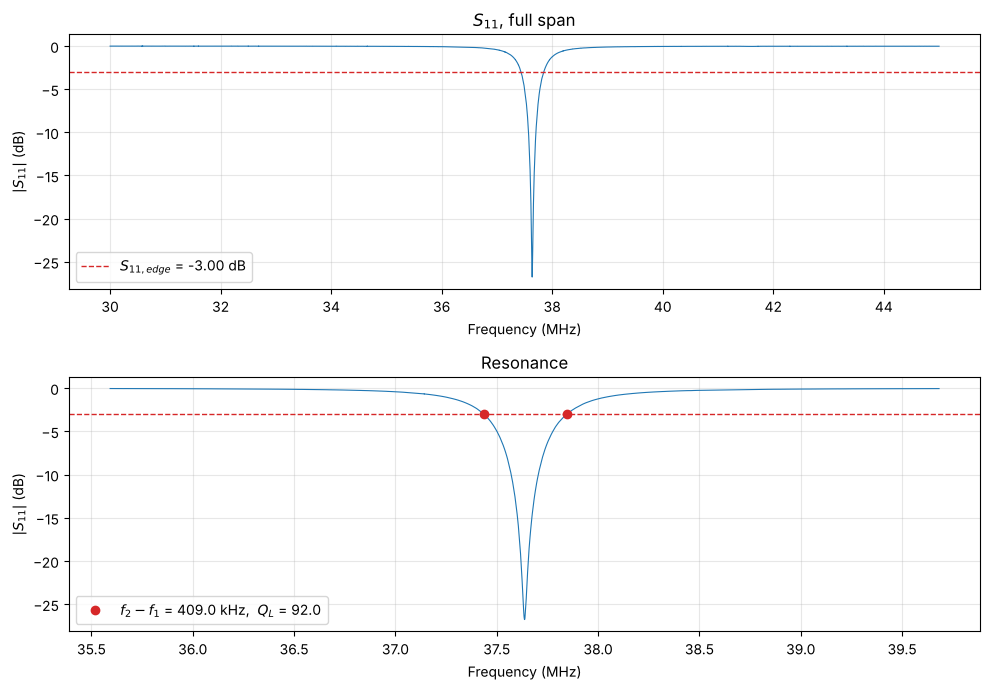

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7))
lvl = S11_edge + 10 * np.log10(baseline)
ax1.plot(f / 1e6, s11_db, lw=0.8)
ax1.axhline(lvl, color="C3", ls="--", lw=1, label=f"$S_{{11,edge}}$ = {S11_edge:.2f} dB")
ax1.set(xlabel="Frequency (MHz)", ylabel="$|S_{11}|$ (dB)", title="$S_{11}$, full span")
ax1.legend(loc="lower left"); ax1.grid(alpha=0.3)

z = np.abs(f - f0_edge) < 5 * (f2 - f1)
ax2.plot(f[z] / 1e6, s11_db[z], lw=0.8)
ax2.axhline(lvl, color="C3", ls="--", lw=1)
ax2.plot([f1 / 1e6, f2 / 1e6], [lvl, lvl], "o", color="C3",
         label=f"$f_2 - f_1$ = {(f2-f1)/1e3:.1f} kHz,  $Q_L$ = {QL_edge:.1f}")
ax2.set(xlabel="Frequency (MHz)", ylabel="$|S_{11}|$ (dB)", title="Resonance")
ax2.legend(loc="lower left"); ax2.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 10. Q-circle fit (Section 6)

Fit $\rho(f) = A + B/(1 + jQ_L\Omega)$ with $\Omega = f/f_0 - f_0/f$ over $\pm 4(f_2 - f_1)$ around resonance. $A$ and $B$ enter linearly and are solved by linear least squares for each trial $(f_0, Q_L)$.

In [5]:
def circle_fit(f, rho, f0_guess, QL_guess, span=4.0):
    m = np.abs(f - f0_guess) < span * f0_guess / QL_guess
    fw, gw = f[m], rho[m]

    def solve_ab(f0, QL):
        Om = fw / f0 - f0 / fw
        M = np.column_stack([np.ones_like(fw), 1 / (1 + 1j * QL * Om)])
        coef, *_ = np.linalg.lstsq(M, gw, rcond=None)
        return coef, M

    def resid(q):
        coef, M = solve_ab(q[0] * f0_guess, q[1] * QL_guess)
        r = gw - M @ coef
        return np.r_[r.real, r.imag]

    sol = least_squares(resid, [1.0, 1.0], x_scale=[1e-4, 0.05], method="lm")
    f0, QL = sol.x[0] * f0_guess, sol.x[1] * QL_guess
    (A, B), _ = solve_ab(f0, QL)
    model = lambda ff: A + B / (1 + 1j * QL * (ff / f0 - f0 / ff))
    return dict(f0=f0, QL=QL, A=A, B=B, mask=m, model=model,
                rms=np.sqrt(np.mean(sol.fun ** 2)))

fit = circle_fit(f, rho, f0_edge, QL_edge)
A, B, f0, QL = fit["A"], fit["B"], fit["f0"], fit["QL"]
print(f"f0                 {f0/1e6:.5f} MHz")
print(f"Q_L                {QL:.2f}")
print(f"A (detuned)        {A.real:+.4f} {A.imag:+.4f}j   |A| = {abs(A):.4f}")
print(f"A + B (resonance)  {(A+B).real:+.4f} {(A+B).imag:+.4f}j")
print(f"rms residual       {fit['rms']:.2e}")

f0                 37.63632 MHz
Q_L                93.62
A (detuned)        +0.9852 -0.1490j   |A| = 0.9964
A + B (resonance)  -0.0434 +0.0005j
rms residual       2.88e-03


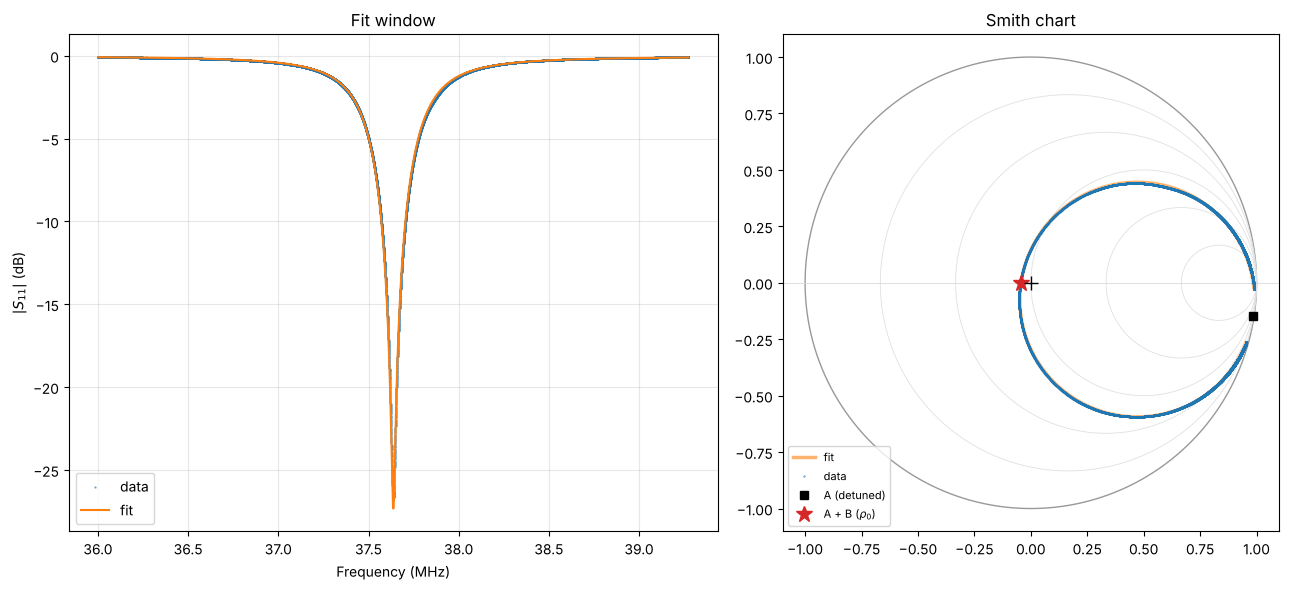

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw=dict(width_ratios=[1.3, 1]))
m = fit["mask"]
ff = np.linspace(f[m][0], f[m][-1], 3000)
g = fit["model"](ff)

ax1.plot(f[m] / 1e6, s11_db[m], ".", ms=1.5, alpha=0.5, label="data")
ax1.plot(ff / 1e6, 20 * np.log10(np.abs(g)), color="C1", lw=1.5, label="fit")
ax1.set(xlabel="Frequency (MHz)", ylabel="$|S_{11}|$ (dB)", title="Fit window")
ax1.legend(); ax1.grid(alpha=0.3)

t = np.linspace(0, 2 * np.pi, 400)
ax2.plot(np.cos(t), np.sin(t), color="0.6", lw=1)
for r in (0.2, 0.5, 1, 2, 5):
    ax2.plot(r / (1 + r) + np.cos(t) / (1 + r), np.sin(t) / (1 + r), color="0.88", lw=0.6)
ax2.axhline(0, color="0.85", lw=0.6)
ax2.plot(g.real, g.imag, color="C1", lw=2.5, alpha=0.6, label="fit")
ax2.plot(rho.real[m], rho.imag[m], ".", ms=0.8, color="C0", label="data")
ax2.plot(A.real, A.imag, "s", color="k", label="A (detuned)")
ax2.plot((A + B).real, (A + B).imag, "*", color="C3", ms=12, label=r"A + B ($\rho_0$)")
ax2.plot(0, 0, "+", color="k", ms=10)
ax2.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), aspect="equal", title="Smith chart")
ax2.legend(loc="lower left", fontsize=8)
fig.tight_layout(); plt.show()

## 11. Coupling, $Q_u$ and $Q_e$ (Sections 5–6)

In [7]:
rho0 = abs(A + B) / abs(A)                   # |ρ0| referenced to the detuned point
beta_under = (1 - rho0) / (1 + rho0)
beta_over = (1 + rho0) / (1 - rho0)

d = abs(B) / abs(A)
encloses = d > 1                              # circle encloses the origin
beta = beta_over if encloses else beta_under
beta_d = d / (2 - d)
Qu = (1 + beta) * QL
Qe = Qu / beta

print(f"|ρ0|               {rho0:.4f}  ({20*np.log10(rho0):.2f} dB)")
print(f"β branches         {beta_under:.4f} (under) / {beta_over:.4f} (over)")
print(f"d = |B|/|A|        {d:.4f}  -> circle {'encloses' if encloses else 'excludes'} the origin")
print(f"β                  {beta:.4f}  ({'over' if encloses else 'under'}-coupled)")
print(f"β = d/(2-d)        {beta_d:.4f}   (check)")
print(f"Q_u = (1+β) Q_L    {Qu:.1f}")
print(f"Q_e = Q_u/β        {Qe:.1f}")

|ρ0|               0.0436  (-27.21 dB)
β branches         0.9165 (under) / 1.0911 (over)
d = |B|/|A|        1.0432  -> circle encloses the origin
β                  1.0911  (over-coupled)
β = d/(2-d)        1.0902   (check)
Q_u = (1+β) Q_L    195.8
Q_e = Q_u/β        179.4


Sensitivity to the fit window:

In [8]:
rows = []
for span in (1, 2, 4, 8, 15):
    r = circle_fit(f, rho, f0_edge, QL_edge, span=span)
    r0 = abs(r["A"] + r["B"]) / abs(r["A"])
    b = (1 + r0) / (1 - r0) if abs(r["B"]) > abs(r["A"]) else (1 - r0) / (1 + r0)
    rows.append({"Fit window": f"±{span} (f<sub>2</sub> − f<sub>1</sub>)",
                 "Q<sub>L</sub>": r["QL"], "β": b, "Q<sub>u</sub>": (1 + b) * r["QL"]})
sens = pd.DataFrame(rows)
display(table(sens, "Sensitivity to the fit window",
              {"Q<sub>L</sub>": "{:.2f}", "β": "{:.4f}", "Q<sub>u</sub>": "{:.1f}"}))

Fit window,QL,β,Qu
±1 (f2 − f1),93.35,1.0974,195.8
±2 (f2 − f1),93.31,1.0930,195.3
±4 (f2 − f1),93.62,1.0911,195.8
±8 (f2 − f1),94.36,1.0902,197.2
±15 (f2 − f1),95.69,1.0897,200.0


## 12. Voltage gain across the EOM (Section 7)

In [9]:
w0 = 2 * np.pi * f0

def gain_from_C(C_eff):
    return np.sqrt(Qu * (1 - rho0**2) / (w0 * C_eff * Z0))

def gain_from_L(L):
    return np.sqrt(w0 * L / Z0) * np.sqrt(Qu * (1 - rho0**2))

def C_eff_from_shift(f0_before, f0_after, dC):
    return dC / ((f0_before / f0_after) ** 2 - 1)

cases = {                                     # edit with measured values
    "C_eff = 14.0 pF (EOM)":        1 / (w0**2 * 14.0e-12),
    "C_eff = 17.3 pF (EOM + trim)": 1 / (w0**2 * 17.3e-12),
    "L = 0.79 µH":                  0.79e-6,
}
print(f"1 - |ρ0|² = {1 - rho0**2:.4f},  Q_u = {Qu:.1f}")

gain_tab = pd.DataFrame([{
    "Case": name,
    "L (µH)": L * 1e6,
    "C<sub>eff</sub> (pF)": 1 / (w0**2 * L) * 1e12,
    "R<sub>p</sub> (kΩ)": Qu * w0 * L / 1e3,
    "G": gain_from_L(L),
    "G (dB)": 20 * np.log10(gain_from_L(L)),
} for name, L in cases.items()])
display(table(gain_tab, "EOM voltage gain at resonance",
              {"L (µH)": "{:.3f}", "C<sub>eff</sub> (pF)": "{:.2f}", "R<sub>p</sub> (kΩ)": "{:.1f}",
               "G": "{:.1f}", "G (dB)": "{:.1f}"}))

# With a measured shift, e.g. ΔC = 3.3 pF moving f0 from f0_before to f0_after:
# C_eff = C_eff_from_shift(f0_before, f0_after, 3.3e-12); print(gain_from_C(C_eff))

1 - |ρ0|² = 0.9981,  Q_u = 195.8


Case,L (µH),Ceff (pF),Rp (kΩ),G,G (dB)
C_eff = 14.0 pF (EOM),1.277,14.00,59.1,34.4,30.7
C_eff = 17.3 pF (EOM + trim),1.034,17.30,47.9,30.9,29.8
L = 0.79 µH,0.790,22.64,36.6,27.0,28.6


## 13. Summary

In [10]:
L_mid = cases["L = 0.79 µH"]
G_mid = gain_from_L(L_mid)
rng = lambda col, fmt: f"{sens[col].min():{fmt}} – {sens[col].max():{fmt}}"
summary = pd.DataFrame([
    ("Resonant frequency",          "f<sub>0</sub>",            f"{f0/1e6:.3f} MHz",          "—",                         "10"),
    ("Reflection at resonance",     "S<sub>11,0</sub>",         f"{20*np.log10(rho0):.1f} dB", "—",                        "10"),
    ("Band-edge level",             "S<sub>11,edge</sub>",      f"{S11_edge:.2f} dB",         "—",                         "4, 9"),
    ("Half-power bandwidth",        "f<sub>2</sub> − f<sub>1</sub>", f"{(f2-f1)/1e3:.0f} kHz", "—",                        "3, 9"),
    ("Loaded Q (edge level)",       "Q<sub>L</sub>",            f"{QL_edge:.1f}",             "—",                         "5, 9"),
    ("Loaded Q (Q-circle fit)",     "Q<sub>L</sub>",            f"{QL:.1f}",                  rng("Q<sub>L</sub>", ".1f"), "6, 10"),
    ("Coupling coefficient",        "β",                        f"{beta:.3f} ({'over' if encloses else 'under'}-coupled)", rng("β", ".3f"), "6, 11"),
    ("Unloaded Q",                  "Q<sub>u</sub>",            f"{Qu:.0f}",                  rng("Q<sub>u</sub>", ".0f"), "5, 11"),
    ("External Q",                  "Q<sub>e</sub>",            f"{Qe:.0f}",                  "—",                         "5, 11"),
    ("Parallel loss resistance",    "R<sub>p</sub>",            f"{Qu*w0*L_mid/1e3:.1f} kΩ",  "—",                         "7.4, 12"),
    ("EOM voltage gain",            "G",                        f"{G_mid:.1f} ({20*np.log10(G_mid):.1f} dB)", "—",        "7.5, 12"),
], columns=["Quantity", "Symbol", "Value", "Fit-window range", "Section"])
display(table(summary, f"Summary of {FILE} (R<sub>p</sub> and G for L = {L_mid*1e6:.3f} µH, C<sub>eff</sub> = {1/(w0**2*L_mid)*1e12:.2f} pF)"))

Quantity,Symbol,Value,Fit-window range,Section
Resonant frequency,f0,37.636 MHz,—,10
Reflection at resonance,"S11,0",-27.2 dB,—,10
Band-edge level,"S11,edge",-3.00 dB,—,"4, 9"
Half-power bandwidth,f2 − f1,409 kHz,—,"3, 9"
Loaded Q (edge level),QL,92.0,—,"5, 9"
Loaded Q (Q-circle fit),QL,93.6,93.3 – 95.7,"6, 10"
Coupling coefficient,β,1.091 (over-coupled),1.090 – 1.097,"6, 11"
Unloaded Q,Qu,196,195 – 200,"5, 11"
External Q,Qe,179,—,"5, 11"
Parallel loss resistance,Rp,36.6 kΩ,—,"7.4, 12"


## References

[1] R. S. Kwok and J.-F. Liang, "Characterization of high-Q resonators for microwave-filter applications," *IEEE Trans. Microwave Theory Tech.*, vol. 47, no. 1, pp. 111–114, Jan. 1999.

[2] D. Kajfez, "Linear fractional curve fitting for measurement of high Q factors," *IEEE Trans. Microwave Theory Tech.*, vol. 42, no. 7, pp. 1149–1153, Jul. 1994.

[3] D. M. Pozar, *Microwave Engineering*, 4th ed., Wiley, 2012.